# Analiza reprezentanc na nogometnem svetovnem prvenstvu 2026
Analizirala bom podatke o reprezentancah na nogometnem svetovnem prvenstvu 2026, ki so objavljeni na spletni strani [StatBunker](https://www.statbunker.com/competitions/Sections?comp_id=790&section_id=1667).
Uporabila bom podatke o [zadetih golih](https://www.statbunker.com/competitions/GoalsFor?comp_id=790), [prejetih golih](https://www.statbunker.com/competitions/GoalsAgainst?comp_id=790), [uspešnosti vratarjev](https://www.statbunker.com/competitions/Top10KeepersCleanSheets?comp_id=790) in [načinih doseganja golov](https://www.statbunker.com/competitions/TeamsGoalScorersTypeOfPlay?comp_id=790). 
Spodaj so podatki predstavljeni s tabelami. Kratice v prvih vrsticah imajo naslednje pomene: **FH** - prvi polčas, **SH** - drugi polčas, **F15** - prvih 15 minut, **L10** - zadnjih 10 minut, **Pld** - število odigranih tekem in **CS** - število tekem brez prejetega gola.

In [45]:
import pandas as pd

goals_for = pd.read_csv("podatki/goals_for.csv")
goals_against = pd.read_csv("podatki/goals_against.csv")
clean_sheets = pd.read_csv("podatki/clean_sheets.csv")
goal_types = pd.read_csv("podatki/goal_types.csv")

## Zadeti goli

In [46]:
goals_for = goals_for.replace("-", 0)
goals_for

,Goals For,Clubs,FH,SH,F15,L10,Pld
0,20,England,9,11,2,5,8
1,20,France,5,15,2,4,8
2,19,Argentina,6,13,1,10,8
3,14,Spain,7,7,1,4,8
4,14,Belgium,4,10,1,6,6
5,13,Norway,6,7,0,3,6
6,11,Germany,4,7,2,2,4
7,11,Netherlands,4,7,3,1,4
8,11,United States,8,3,3,2,5
9,10,Senegal,2,8,1,3,4


Najprej poglejmo, katere reprezentance so na svetovnem prvenstvu zadele največ golov.

In [47]:
goals_for[["Clubs", "Goals For"]].head(10)

,Clubs,Goals For
0,England,20
1,France,20
2,Argentina,19
3,Spain,14
4,Belgium,14
5,Norway,13
6,Germany,11
7,Netherlands,11
8,United States,11
9,Senegal,10


Sedaj deset reprezentanc z največ zadetimi goli prikažimo še s stolpičnim diagramom.

<Axes: title={'center': 'Reprezentane z največ zadetimi goli'}, xlabel='Reprezentance', ylabel='Zadeti goli'>

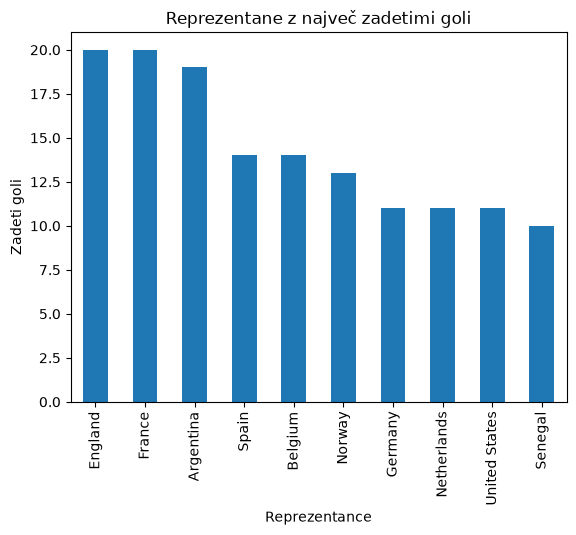

In [51]:
goals_for.head(10).plot.bar(x="Clubs", y="Goals For", xlabel="Reprezentance", ylabel="Zadeti goli", title="Reprezentane z največ zadetimi goli", legend=False)

Poglejmo, katere reprezentance so na prvenstvu zadele vsaj 10 golov.

In [52]:
vsaj_10_golov = goals_for[goals_for["Goals For"] >= 10]
vsaj_10_golov

,Goals For,Clubs,FH,SH,F15,L10,Pld
0,20,England,9,11,2,5,8
1,20,France,5,15,2,4,8
2,19,Argentina,6,13,1,10,8
3,14,Spain,7,7,1,4,8
4,14,Belgium,4,10,1,6,6
5,13,Norway,6,7,0,3,6
6,11,Germany,4,7,2,2,4
7,11,Netherlands,4,7,3,1,4
8,11,United States,8,3,3,2,5
9,10,Senegal,2,8,1,3,4


Poglejmo, katere izmed reprezentanc z vsaj 10 zadetimi goli so jih največ dosegle v drugem polčasu.

In [7]:
vsaj_10_golov.sort_values("SH", ascending=False)

,Goals For,Clubs,FH,SH,F15,L10,Pld
9,10,Senegal,2,8,1,3,4
12,10,Switzerland,2,8,1,3,6
3,14,Spain,7,7,1,4,8
5,13,Norway,6,7,0,3,6
6,11,Germany,4,7,2,2,4
7,11,Netherlands,4,7,3,1,4
11,10,Mexico,4,6,1,1,5
13,10,Morocco,4,6,1,4,6
10,10,Brazil,6,4,1,2,5
8,11,United States,8,3,3,2,5


V spodnji tabeli so prikazane reprezentance z vsaj 10 zadetmi goli, ki so jih največ dosegle v zadnjih 10 minutah tekem.

In [8]:
vsaj_10_golov["L10"] = vsaj_10_golov["L10"].astype(int)
vsaj_10_golov.sort_values("L10", ascending=False)

,Goals For,Clubs,FH,SH,F15,L10,Pld
2,19,Argentina,6,13,1,10,8
4,14,Belgium,4,10,1,6,6
0,20,England,9,11,2,5,8
1,20,France,5,15,2,4,8
3,14,Spain,7,7,1,4,8
13,10,Morocco,4,6,1,4,6
5,13,Norway,6,7,0,3,6
9,10,Senegal,2,8,1,3,4
12,10,Switzerland,2,8,1,3,6
6,11,Germany,4,7,2,2,4


## Prejeti goli

In [9]:
goals_against = goals_against.replace("-", 0)
goals_against

,Goals Against,Clubs,FH,SH,F15,L10,Pld
0,1,Spain,1,0,0,0,8
1,1,Colombia,0,1,0,0,5
2,3,Iran,2,1,2,0,3
3,3,Ghana,2,1,1,1,4
4,3,Portugal,1,2,0,1,5
5,3,Mexico,2,1,0,0,5
6,3,South Korea,0,3,0,0,3
7,3,Australia,3,0,2,0,4
8,4,Uruguay,3,1,0,0,3
9,4,South Africa,2,2,2,1,4


Sedaj poglejmo, katere reprezentance pa so na svetovnem prvenstvu prejele najmanj golov.

In [10]:
goals_against[["Clubs", "Goals Against"]].head(10)

,Clubs,Goals Against
0,Spain,1
1,Colombia,1
2,Iran,3
3,Ghana,3
4,Portugal,3
5,Mexico,3
6,South Korea,3
7,Australia,3
8,Uruguay,4
9,South Africa,4


Poglejmo reprezentance, ki so prejele največ 5 golov, in jih razvrstimo glede na število odigranih tekem.

In [11]:
najvec_5_prejetih = goals_against[goals_against["Goals Against"] <= 5]
najvec_5_prejetih.sort_values("Pld", ascending=False)

,Goals Against,Clubs,FH,SH,F15,L10,Pld
0,1,Spain,1,0,0,0,8
1,1,Colombia,0,1,0,0,5
4,3,Portugal,1,2,0,1,5
5,3,Mexico,2,1,0,0,5
13,4,Brazil,2,2,0,1,5
20,5,Germany,4,1,1,0,4
19,5,Japan,0,5,0,1,4
17,5,DR Congo (Zaire),2,3,2,1,4
16,5,Cape Verde,3,2,0,2,4
15,5,Netherlands,0,5,0,2,4


Poglejmo reprezentance, ki so odigrale vsaj 5 tekem in pri tem prejele največ 5 golov.

In [12]:
goals_against[(goals_against["Goals Against"] <= 5) & (goals_against["Pld"] >= 5)]

,Goals Against,Clubs,FH,SH,F15,L10,Pld
0,1,Spain,1,0,0,0,8
1,1,Colombia,0,1,0,0,5
4,3,Portugal,1,2,0,1,5
5,3,Mexico,2,1,0,0,5
13,4,Brazil,2,2,0,1,5


Zanima nas, ali je število prejetih golov povezano s številom odigranih tekem, zato njuno povezavo preverimo z grafom.

<Axes: title={'center': 'Povezava med številom tekem in prejetimi goli'}, xlabel='Število tekem', ylabel='Prejeti goli'>

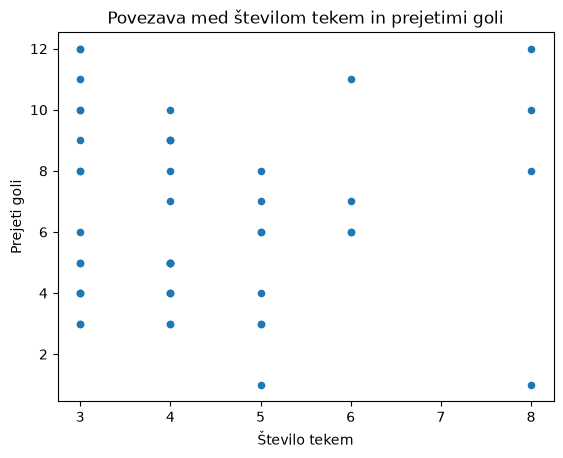

In [53]:
goals_against.plot.scatter(x="Pld", y="Goals Against", xlabel="Število tekem", ylabel="Prejeti goli", title="Povezava med številom tekem in prejetimi goli")

Iz grafa ni razvidna jasna povezava med številom odigranih tekem in številom prejetih golov. Tudi reprezentance z enakim številom odigranih tekem se precej razlikujejo po številu prejetih golov.

## Uspešnost vratarjev

In [16]:
clean_sheets

,Players,Clubs,Nationality,CS,Pld,%
0,Unai Simon,Spain,Spain,7,8,87.50%
1,Raul Rangel,Mexico,Mexico,4,5,80.00%
2,Camilo Vargas,Colombia,Colombia,4,5,80.00%
3,Mike Maignan,France,France,4,8,50.00%
4,Josimar Vozinha,Cape Verde,Cape Verde,2,4,50.00%
5,Patrick Beach,Australia,Australia,2,4,50.00%
6,Matt Freese,United States,United States,2,4,50.00%
7,Yahia Fofana,Ivory Coast,France,2,4,50.00%
8,Alisson,Brazil,Brazil,2,5,40.00%
9,Orlando Gill,Paraguay,Paraguay,2,5,40.00%


Sedaj poglejmo, kateri vrataji so bili najuspešnejši pri branjenju gola.

In [61]:
clean_sheets[["Players", "Clubs", "CS", "Pld"]].head(10)

,Players,Clubs,CS,Pld
0,Unai Simon,Spain,7,8
1,Raul Rangel,Mexico,4,5
2,Camilo Vargas,Colombia,4,5
3,Mike Maignan,France,4,8
4,Josimar Vozinha,Cape Verde,2,4
5,Patrick Beach,Australia,2,4
6,Matt Freese,United States,2,4
7,Yahia Fofana,Ivory Coast,2,4
8,Alisson,Brazil,2,5
9,Orlando Gill,Paraguay,2,5


Zgornjo tabelo prikažemo še s stolpičnim grafom.

<Axes: title={'center': 'Vratarji z največ tekmami brez prejetega gola'}, xlabel='Golmani', ylabel='Število tekem brez prejetega gola'>

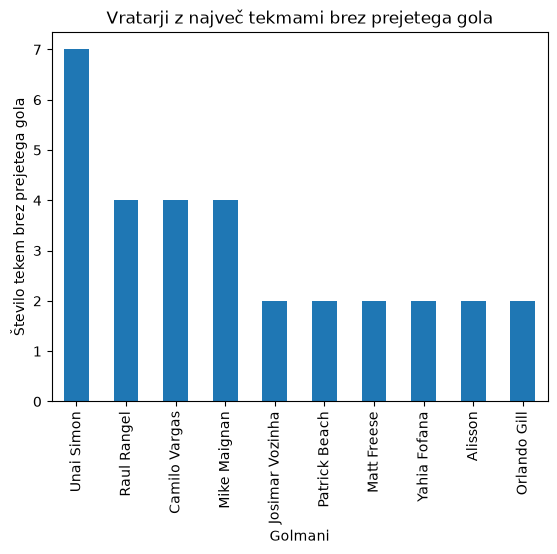

In [60]:
clean_sheets.head(10).plot.bar(x="Players", y="CS", xlabel="Golmani", ylabel="Število tekem brez prejetega gola", title="Vratarji z največ tekmami brez prejetega gola", legend=False)

## Načini doseganja golov

V tabeli je prikazanih 8 načinov doseganja golov. Open play pomeni gole, zadete iz igre, Cross gole po predložkih, Free Kick gole po prostih strelih, Direct Free Kick gole zadete neposredno iz prostega strela, Throw In predstavlja gole po avtu, Penalty gole iz enajstmetrovk, Corner gole po kotu, Other pa vse ostale gole. 

In [62]:
goal_types = goal_types.replace("-", 0)
goal_types

,Clubs,Goals,Open Play,Cross,Free Kick,Direct Free Kick,Throw In,Penalty,Corner,Other
0,France,20,17,1,0,0,0,1,1,0
1,England,20,9,4,0,0,0,3,4,0
2,Argentina,18,9,3,0,2,0,1,3,0
3,Spain,13,8,3,0,0,0,1,1,0
4,Belgium,13,6,5,0,0,0,1,1,0
5,Norway,12,9,2,0,0,0,0,1,0
6,Germany,11,7,2,0,0,0,1,1,0
7,Brazil,10,7,2,0,0,0,1,0,0
8,Morocco,10,7,1,1,0,0,0,1,0
9,Switzerland,10,7,1,0,0,0,2,0,0


Sedaj poglejmo še, koliko golov je 10 reprezentance z največ zadetimi goli doseglo iz igre, po predložkih, iz prostih strelov in iz enajstmetrovk. 

In [63]:
goal_types[["Clubs", "Goals", "Open Play", "Cross", "Free Kick", "Penalty"]].head(10)

,Clubs,Goals,Open Play,Cross,Free Kick,Penalty
0,France,20,17,1,0,1
1,England,20,9,4,0,3
2,Argentina,18,9,3,0,1
3,Spain,13,8,3,0,1
4,Belgium,13,6,5,0,1
5,Norway,12,9,2,0,0
6,Germany,11,7,2,0,1
7,Brazil,10,7,2,0,1
8,Morocco,10,7,1,1,0
9,Switzerland,10,7,1,0,2


Katerih deset reprezentanc je največ golov doseglo iz igre?

In [64]:
goal_types["Open Play"] = goal_types["Open Play"].astype(int)
goal_types.sort_values("Open Play", ascending=False).head(10)

,Clubs,Goals,Open Play,Cross,Free Kick,Direct Free Kick,Throw In,Penalty,Corner,Other
0,France,20,17,1,0,0,0,1,1,0
2,Argentina,18,9,3,0,2,0,1,3,0
5,Norway,12,9,2,0,0,0,0,1,0
1,England,20,9,4,0,0,0,3,4,0
12,Senegal,10,9,0,0,0,0,0,1,0
3,Spain,13,8,3,0,0,0,1,1,0
6,Germany,11,7,2,0,0,0,1,1,0
7,Brazil,10,7,2,0,0,0,1,0,0
8,Morocco,10,7,1,1,0,0,0,1,0
9,Switzerland,10,7,1,0,0,0,2,0,0


Podatke iz zgornje tabele prikažimo še grafično.

<Axes: title={'center': 'Reprezentance z največ goli iz igre'}, xlabel='Reprezentance', ylabel='Število golov iz igre'>

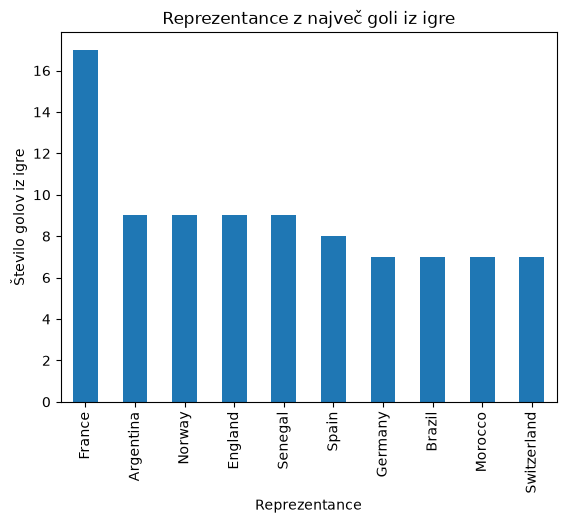

In [65]:
goal_types.sort_values("Open Play", ascending=False).head(10).plot.bar(x="Clubs", y="Open Play", xlabel="Reprezentance", ylabel="Število golov iz igre", title="Reprezentance z največ goli iz igre", legend=False)

Primerjamo načine doseganja golov pri reprezentancah, ki so na prvenstvu dosegle vsaj 10 golov.

In [23]:
goal_types["Cross"] = goal_types["Cross"].astype(int)
goal_types["Free kick"] = goal_types["Free Kick"].astype(int)
goal_types["Penalty"] = goal_types["Penalty"].astype(int)
najboljsi_napad = goal_types[goal_types["Goals"] >= 10]
najboljsi_napad[["Clubs", "Goals", "Open Play", "Cross", "Free Kick", "Penalty"]]

,Clubs,Goals,Open Play,Cross,Free Kick,Penalty
0,France,20,17,1,0,1
1,England,20,9,4,0,3
2,Argentina,18,9,3,0,1
3,Spain,13,8,3,0,1
4,Belgium,13,6,5,0,1
5,Norway,12,9,2,0,0
6,Germany,11,7,2,0,1
7,Brazil,10,7,2,0,1
8,Morocco,10,7,1,1,0
9,Switzerland,10,7,1,0,2


Iz tabele je razvidno, da so reprezentance večino golov dosegle iz igre. Največ golov iz igre je dosegla Francija, in sicer 17 od skupno 20. Anglija je prav tako dosegla 20 golov, vendar le 9 iz igre, več golov pa je dosegla po predložkih in iz enajstmetrovk. Med reprezentancami izstopa tudi Belgija, ki je 5 od 13 golov dosegla po predložkih. Goli po prostih strelih so bili precej redki.

Sedaj naredimo še grafično predstavitev, na kakšne načine so ekipe z vsaj 10 goli dosegale zadetke.

<Axes: title={'center': 'Načini doseganja golov'}, xlabel='Reprezentance', ylabel='Število zadetih golov'>

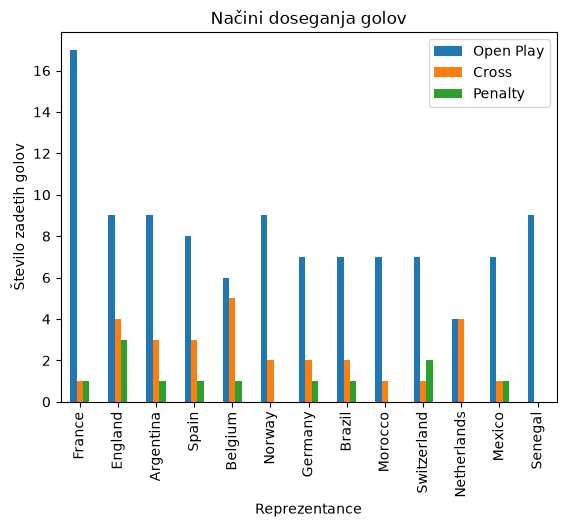

In [66]:
najboljsi_napad.plot.bar(x="Clubs", y=["Open Play", "Cross", "Free Kick", "Penalty"], xlabel="Reprezentance", ylabel="Število zadetih golov", title="Načini doseganja golov")

## Združeni podatki o napadu in obrambi

Podatke o zadetih in prejetih golih združimo v eno tabelo, da lahko primerjamo napadalno in obrambno uspešnost posameznih reprezentanc.

In [25]:
napad = goals_for[["Clubs", "Goals For"]]
obramba = goals_against[["Clubs", "Goals Against"]]
napad_in_obramba = pd.merge(napad, obramba, on="Clubs")
napad_in_obramba

,Clubs,Goals For,Goals Against
0,England,20,12
1,France,20,10
2,Argentina,19,8
3,Spain,14,1
4,Belgium,14,7
5,Norway,13,11
6,Germany,11,5
7,Netherlands,11,5
8,United States,11,8
9,Senegal,10,9


Za reprezentance izračunajmo še razliko med številom zadetih in prejetih golov.

In [26]:
napad_in_obramba["Goal Difference"] = (napad_in_obramba["Goals For"] - napad_in_obramba["Goals Against"])
napad_in_obramba.sort_values("Goal Difference", ascending=False).head(10)

,Clubs,Goals For,Goals Against,Goal Difference
3,Spain,14,1,13
2,Argentina,19,8,11
1,France,20,10,10
0,England,20,12,8
4,Belgium,14,7,7
11,Mexico,10,3,7
6,Germany,11,5,6
7,Netherlands,11,5,6
10,Brazil,10,4,6
16,Portugal,8,3,5


Podatke prikažemo še grafično.

<Axes: title={'center': 'Reprezentance z največjo razliko v golih'}, xlabel='Reprezentance', ylabel='Razlika v golih'>

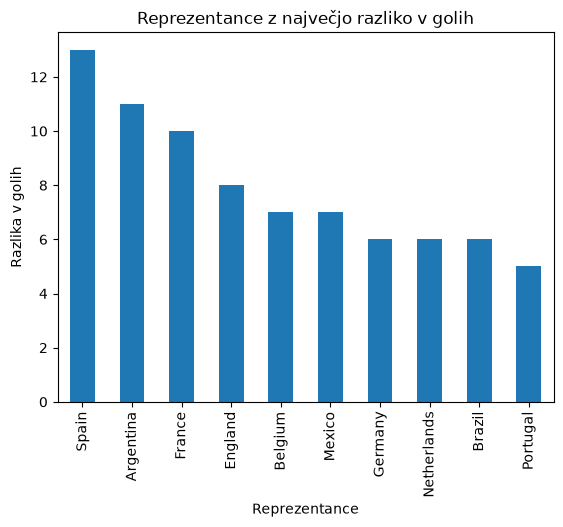

In [67]:
napad_in_obramba.sort_values("Goal Difference", ascending=False).head(10).plot.bar(x="Clubs", y="Goal Difference", xlabel="Reprezentance", ylabel="Razlika v golih", title="Reprezentance z največjo razliko v golih", legend=False)

Poiščimo reprezentance z največjo in najmanjšo razliko med zadetimi in prejetimi goli.

In [28]:
najvecja_razlika = napad_in_obramba["Goal Difference"].max()
najmanjsa_razlika = napad_in_obramba["Goal Difference"].min()
najboljse_reprezentance = napad_in_obramba[napad_in_obramba["Goal Difference"] == najvecja_razlika]
najslabse_reprezentance = napad_in_obramba[napad_in_obramba["Goal Difference"] == najmanjsa_razlika]
najboljse = najboljse_reprezentance["Clubs"].tolist()
najslabse = najslabse_reprezentance["Clubs"].tolist()
print(f'Največjo razliko v golih ({najvecja_razlika}) ima ' f'{", ".join(najboljse)}, najmanjšo razliko ({najmanjsa_razlika}) pa ' f'{", ".join(najslabse)}.')

Največjo razliko v golih (13) ima Spain, najmanjšo razliko (-11) pa Iraq.


Poglejmo, ali obstaja povezava med številom doseženih in prejetih golov posameznih reprezentanc.

<Axes: title={'center': 'Povezava med doseženimi in prejetimi goli'}, xlabel='Doseženi goli', ylabel='Prejeti goli'>

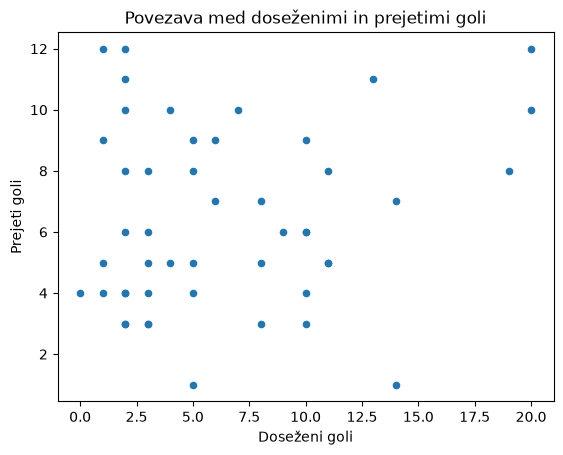

In [68]:
napad_in_obramba.plot.scatter(x="Goals For", y="Goals Against", xlabel="Doseženi goli", ylabel="Prejeti goli", title="Povezava med doseženimi in prejetimi goli")

Med številom doseženih in prejetih golov ni opaziti jasne povezave. Nekatere reprezentance z veliko zadetimi goli so jih tudi veliko prejele, medtem ko so druge ob podobnem številu doseženih zadetkov prejele precej manj golov.

Reprezentance razdelimo v skupine glede na razliko med številom zadetih in prejetih golov. Nato bomo primerjali povprečne rezultate posameznih skupin.

In [30]:
def po_razliki(n):
    if n < 0:
        return "Negativna"
    elif n == 0:
        return "Ničelna"
    elif n <= 5:
        return "1-5"
    elif n <= 10:
        return "6-10"
    else:
        return "Več kot 10"

napad_in_obramba["Skupina po razliki"] = (napad_in_obramba["Goal Difference"].apply(po_razliki))
napad_in_obramba

,Clubs,Goals For,Goals Against,Goal Difference,Skupina po razliki
0,England,20,12,8,6-10
1,France,20,10,10,6-10
2,Argentina,19,8,11,Več kot 10
3,Spain,14,1,13,Več kot 10
4,Belgium,14,7,7,6-10
5,Norway,13,11,2,1-5
6,Germany,11,5,6,6-10
7,Netherlands,11,5,6,6-10
8,United States,11,8,3,1-5
9,Senegal,10,9,1,1-5


Sedaj reprezentance združimo po skupinah in nato primerjamo povprečne rezultate med skupinami.

In [71]:
skupine = napad_in_obramba.groupby("Skupina po razliki")
tabela_skupin = round(skupine.mean(numeric_only=True), 2)
tabela_skupin[["Goals For", "Goals Against", "Goal Difference"]].sort_values("Goal Difference", ascending=True)

,Goals For,Goals Against,Goal Difference
Skupina po razliki,,,
Negativna,2.84,7.04,-4.20
Ničelna,3.67,3.67,0.00
1-5,8.82,6.00,2.82
6-10,13.71,6.57,7.14
Več kot 10,16.50,4.50,12.00


Sedaj nas zanima, koliko reprezentanc je v posamezni skupini.

In [32]:
st_reprezentanc_po_skupinah = napad_in_obramba.groupby("Skupina po razliki").size()
st_reprezentanc_po_skupinah = st_reprezentanc_po_skupinah.reindex(["Negativna", "Ničelna", "1-5", "6-10", "Več kot 10"])
st_reprezentanc_po_skupinah

Skupina po razliki
Negativna     25
Ničelna        3
1-5           11
6-10           7
Več kot 10     2
dtype: int64

In [33]:
najpogostejsa_skupina = st_reprezentanc_po_skupinah.idxmax()
st_v_najpogostejsi_skupini = st_reprezentanc_po_skupinah.max()
print(f'Največ reprezentanc spada v skupino {najpogostejsa_skupina}, ' f'in sicer {st_v_najpogostejsi_skupini}.')

Največ reprezentanc spada v skupino Negativna, in sicer 25.


Poiščimo reprezentance, ki so dosegle vsaj 10 golov in jih hkrati prejele največ 5.

In [34]:
napad_in_obramba[(napad_in_obramba["Goals For"] >= 10) & (napad_in_obramba["Goals Against"] <= 5)]

,Clubs,Goals For,Goals Against,Goal Difference,Skupina po razliki
3,Spain,14,1,13,Več kot 10
6,Germany,11,5,6,6-10
7,Netherlands,11,5,6,6-10
10,Brazil,10,4,6,6-10
11,Mexico,10,3,7,6-10


V tabelo bomo dodali še število odigranih tekem.

In [35]:
tekme = goals_for[["Clubs", "Pld"]]
napad_in_obramba = pd.merge(napad_in_obramba, tekme, on="Clubs")
napad_in_obramba

,Clubs,Goals For,Goals Against,Goal Difference,Skupina po razliki,Pld
0,England,20,12,8,6-10,8
1,France,20,10,10,6-10,8
2,Argentina,19,8,11,Več kot 10,8
3,Spain,14,1,13,Več kot 10,8
4,Belgium,14,7,7,6-10,6
5,Norway,13,11,2,1-5,6
6,Germany,11,5,6,6-10,4
7,Netherlands,11,5,6,6-10,4
8,United States,11,8,3,1-5,5
9,Senegal,10,9,1,1-5,4


Poglejmo, ali imajo reprezentance z več odigranimi tekmami praviloma tudi večjo razliko med zadetimi in prejetimi goli.

<Axes: title={'center': 'Povezava med številom tekem in razliko v golih'}, xlabel='Število odigranih tekem', ylabel='Razlika v golih'>

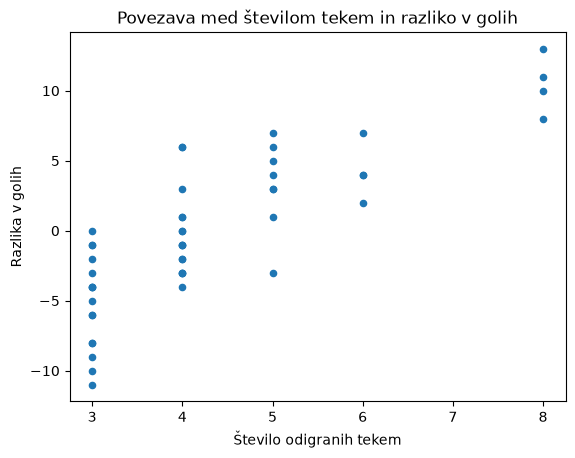

In [69]:
napad_in_obramba.plot.scatter(x="Pld", y="Goal Difference", xlabel="Število odigranih tekem", ylabel="Razlika v golih", title="Povezava med številom tekem in razliko v golih")

Iz grafa je razvidno, da obstaja povezava med številom odigranih tekem in razliko v golih. Reprezentance z več odigranimi tekmami imajo praviloma večjo razliko v golih. Reprezentance, ki so odigrale 3 tekme, imajo večinoma negativno razliko, medtem ko imajo reprezentance z 8 odigranimi tekmami visoko pozitivno razliko. Takšen rezultat je pričakovan, saj so reprezentance, ki so odigrale 3 tekme izpadle že v skupinskem delu. Posledično so imele manj možnosti za doseganje golov, hkrati pa njihovo zgodnje izpadanje kaže tudi na slabšo uspešnost oziroma več prejetih golov. Število odigranih tekem je zato povezano tudi s številom doseženih in prejetih golov.